# Training 

(Right now it looks like lab 6 because I have no idea how to open a jupyter notebook on vs code and the aesthetic of vs code looks the best I don't wanna work on other app :-)

In [30]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torchvision.models import ResNet50_Weights, resnet50
from torchvision.io import read_image

import matplotlib.pyplot as plt

import os
import time

CSV_PATH    = "sculpturesData.csv"
IMG_DIR     = "images"
LABEL_COL   = "Origin"
IMG_EXTS    = [".jpg", ".jpeg", ".png"]

SEED        = 5000
BATCH_SIZE  = 32
EPOCHS      = 8
LR          = 1e-4
NUM_WORKERS = 0
USE_CLASS_WEIGHTS = True # There are classes that has much less number of data

DEVICE = ("cuda" if torch.cuda.is_available()
          else "cpu")
print("device:", DEVICE)

allData = pd.read_csv(CSV_PATH, index_col=0)   # first column (the image file name) becomes the index
print(allData)

device: cpu
                                                  Title    Origin  \
0                                      Sitzender Buddha  Thailand   
1     Buddha in Bhumisparsa-Mudra beschirmt von Naga...  Thailand   
2                                      Liegender Buddha  Thailand   
3     Buddha in Bhumisparsa-Mudra und ein Jünger in ...   Myanmar   
4                                      Stehender Buddha   Myanmar   
...                                                 ...       ...   
1943                                     Head of Buddha     China   
1944                           Head of Emaciated Buddha  Gandhara   
1945               Relief of Śākyamuni Buddha Preaching  Gandhara   
1946                          Standing Śākyamuni Buddha  Gandhara   
1947                          Standing Śākyamuni Buddha  Gandhara   

               Source                                              Image  
0     Reitberg Museum  https://rietberg.ch/collection/Items/10686/_co...  
1     Rei

In [33]:
def find_image(name):
    name = str(name)
    if os.path.isfile(os.path.join(IMG_DIR, name)):          # index already includes the extension
        return os.path.join(IMG_DIR, name)
    for ext in IMG_EXTS:
        p = os.path.join(IMG_DIR, name + ext)
        if os.path.isfile(p):
            return p
    return None

allData["path"] = [find_image(i) for i in allData.index]
allData = allData.dropna(subset=["path", LABEL_COL])

CLASSES = sorted(allData[LABEL_COL].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
allData["label"] = allData[LABEL_COL].map(class_to_idx)
print("Number of Images:", len(allData))
print("Number of Classes:", len(CLASSES))
print(allData[LABEL_COL].value_counts().to_string())

Number of Images: 1948
Number of Classes: 10
Origin
China        801
Myanmar      304
Thailand     166
Japan        135
India        127
Gandhara     122
Tibet        107
Indonesia     87
Nepal         63
Cambodia      36


In [35]:
# Divide to train, val, test
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []

# Divide each class to ensure we have data from every classes in three sets
for c in range(len(CLASSES)):
    rows = np.where(allData["label"].values == c)[0]
    rows = rng.permutation(rows)

    # use 70, 15, 15 instead because there are class with much less data
    # try to get more training data
    n_tr = int(len(rows) * 0.7)
    n_va = int(len(rows) * 0.15)
    train_idx += rows[:n_tr].tolist()
    val_idx   += rows[n_tr:n_tr + n_va].tolist()
    test_idx  += rows[n_tr + n_va:].tolist()

trainSet = allData.iloc[rng.permutation(train_idx)]
valSet   = allData.iloc[rng.permutation(val_idx)]
testSet  = allData.iloc[rng.permutation(test_idx)]

trainSet.to_csv("./trainSet.csv")
valSet.to_csv("./valSet.csv")
testSet.to_csv("./testSet.csv")

print(f"train {len(trainSet)}   val {len(valSet)}   test {len(testSet)}")
print(pd.DataFrame({"train": trainSet[LABEL_COL].value_counts(),
                    "val":   valSet[LABEL_COL].value_counts(),
                    "test":  testSet[LABEL_COL].value_counts()}))

train 1358   val 289   test 301
           train  val  test
Origin                     
China        560  120   121
Myanmar      212   45    47
Thailand     116   24    26
Japan         94   20    21
India         88   19    20
Gandhara      85   18    19
Tibet         74   16    17
Indonesia     60   13    14
Nepal         44    9    10
Cambodia      25    5     6


### Code from lab, try to classified the image using imageNet Data

image (3, 491, 328) torch.uint8, values 0 to 255


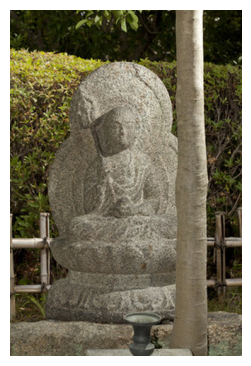

In [15]:
IMG_PATH = "524.jpg"

image = read_image(IMG_PATH)
print(f"image {tuple(image.shape)} {image.dtype}, "
      f"values {int(image.min())} to {int(image.max())}")
plt.figure(figsize=(8, 4.5))
plt.imshow(image.permute(1, 2, 0))
plt.axis("off"); plt.grid(False)
plt.show()

In [16]:
weights = ResNet50_Weights.IMAGENET1K_V1
model = resnet50(weights=weights)
tf_default = weights.transforms()

print(tf_default)
print()
print(f"  resize to      {tf_default.resize_size}")
print(f"  then crop to   {tf_default.crop_size}")
print(f"  mean           {tf_default.mean}")
print(f"  std            {tf_default.std}")

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)

  resize to      [256]
  then crop to   [224]
  mean           [0.485, 0.456, 0.406]
  std            [0.229, 0.224, 0.225]


In [17]:
from torchvision import datasets
from torch.utils.data import DataLoader, Subset
from torchvision import transforms as T

tf = T.Compose([
                    T.Resize(224),
                    T.ToTensor(),
                    T.Normalize(mean = tf_default.mean, std = tf_default.std)
])

train_full = datasets.CIFAR10("data", train=True, download=True, transform=tf)
val_full = datasets.CIFAR10("data", train=False, download=True, transform=tf)
CLASSES = train_full.classes

g = torch.Generator().manual_seed(SEED)
tri = torch.randperm(len(train_full), generator=g)[:5_000].tolist()
vai = torch.randperm(len(val_full), generator=g)[:2_000].tolist()

train_loader = DataLoader(Subset(train_full, tri), batch_size=64, shuffle=True,
                          num_workers=2, generator=g)
val_loader = DataLoader(Subset(val_full, vai), batch_size=64, num_workers=2)

print(f"train {len(tri):,}   val {len(vai):,}   classes {CLASSES}")

train 5,000   val 2,000   classes ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [18]:
def build(pretrained, freeze):
    torch.manual_seed(SEED)
    model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)

    if freeze == True:
        for param in model.parameters():
            param.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, 10)

    return model.to(DEVICE)

for pre, frz, name in [(True, False, "fine-tune")]:
    m = build(pre, frz)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"  {name:10s} {n:>12,} trainable of "
          f"{sum(p.numel() for p in m.parameters()):,}")

  fine-tune    23,528,522 trainable of 23,528,522


In [ ]:
from torchvision.models.detection import (fasterrcnn_resnet50_fpn,
                                          FasterRCNN_ResNet50_FPN_Weights)

det_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
det_tf = det_weights.transforms()
COCO = det_weights.meta["categories"]

print(f"detector preprocessing mean: {getattr(det_tf, 'mean', None)}")
print(f"detector preprocessing std : {getattr(det_tf, 'std', None)}")
print(f"COCO classes: {len(COCO)}")

detector = fasterrcnn_resnet50_fpn(weights=det_weights).eval().to(DEVICE)
with torch.no_grad():
    out = detector([det_tf(image).to(DEVICE)])[0]

boxes = out["boxes"].cpu()
labels = [COCO[i] for i in out["labels"].cpu()]
scores = out["scores"].cpu()
print(f"\nthe model returned {len(boxes)} detections")
for b, l, s in zip(boxes[:8], labels[:8], scores[:8]):
    print(f"  {l:14s} {s:.3f}  [{b[0]:7.0f} {b[1]:7.0f} {b[2]:7.0f} {b[3]:7.0f}]")

detector preprocessing mean: None
detector preprocessing std : None
COCO classes: 91

the model returned 8 detections
  toilet         0.820  [    161     428     217     488]
  elephant       0.677  [     43      65     252     351]
  vase           0.603  [    160     432     214     489]
  teddy bear     0.504  [     46      70     246     374]
  toilet         0.099  [    155     400     235     482]
  person         0.063  [     30      79     263     435]
  toilet         0.053  [    184     433     229     482]
  couch          0.051  [     61     281     223     453]


definitely not correct but can see where this is coming from.